# Main 10 — longitudinal circle diagrams and final audit

Create the four formal longitudinal 26-node/168-edge circle diagrams and audit the complete Main pipeline.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `main`; step 10 of 10
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("main_01_setup_load.py")
_run_step("main_02_demographics_hc_reference.py")
_run_step("main_03_baseline_discovery_sensitivity.py")
_run_step("main_04_longitudinal_paired_clinical.py")
_run_step("main_05_interactions_mwc.py")
_run_step("main_06_spatial_replication_report.py")
_run_step("main_07_core_figures_heatmaps.py")
_run_step("main_08_circle_diagrams_checks.py")
_run_step("main_09_five_global_indexes.py")


MetaFL package root: .
Main-analysis output root: ./outputs/main_analyses
Cortical IDs: [3, 4, 5, 6, 19, 20, 21, 22, 25, 26, 31, 32]
Limbic IDs: [41, 42, 43, 44, 45, 46, 75, 76, 77, 78, 79, 80, 151, 152]
Cross-edge family: 168


,cohort,clinical_n,ses01_complete_n
0,HC,23,23
1,nTRD,25,25
2,TRD1,35,35
3,TRD2,104,104


,cohort,baseline_n,metric
0,nTRD,25,age/sex-adjusted normative-SC MwC deviation z
1,TRD1,35,age/sex-adjusted normative-SC MwC deviation z
2,TRD2,104,age/sex-adjusted normative-SC MwC deviation z


Written: ./outputs/main_analyses/demographic_and_clinical_summary.xlsx


,variable,HC,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Age,50.91 (17.04); n=23,52.32 (12.22); n=25,48.20 (15.52); n=35,39.09 (13.96); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.561396,Welch t-test,0.003261
1,"Female, n (%)",14 (60.87%); n=23,14 (56.00%); n=25,25 (71.43%); n=35,73 (70.19%); n=104,"Pearson chi-square: HC, nTRD, TRD1",0.443311,Fisher exact test,1.000000
2,Education,14.17 (3.46); n=23,13.44 (3.86); n=25,13.14 (3.83); n=35,14.57 (2.81); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.587829,Welch t-test,0.048544


...

,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,37,12,0,0,0,0,0
1,rTMS,34,10,0,1,0,0,0
2,sham,33,7,0,0,8,0,0


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,37,0.322443,-0.025557,-0.348000,-0.572619,-0.123381,-0.516559,-3.142105,0.003349,33,0.006111,0.071019,0.064908,-0.181350,0.311167,0.093460,0.536889,0.595058,-0.416926,-0.743816,-0.090037,-2.546487,-0.299102,66.0,0.013222,70,0.959085,2.229230e-02,0.955781,0.158664
12,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,34,-0.273847,0.514968,0.788815,0.318728,1.258902,0.585489,3.413956,0.001712,33,-0.183835,-0.666455,-0.482620,-1.379927,0.414687,-0.190715,-1.095573,0.281443,1.276207,0.296265,2.256148,2.602498,0.311564,63.0,0.011524,67,0.780512,1.271153e-08,0.383674,0.115241
13,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,34,-0.087030,0.377345,0.464375,0.132766,0.795984,0.488612,2.849074,0.007495,33,-0.324140,-0.963345,-0.639205,-1.564791,0.286381,-0.244874,-1.406696,0.169156,1.106516,0.145622,2.067410,2.301186,0.278456,63.0,0.024701,67,0.653186,2.641524e-11,0.288406,0.123506
14,rTMS,edge,AAL3_026_OFCmed_R,AAL3_077_Putamen_L,34,-0.413277,0.064399,0.477676,0.042754,0.912599,0.383216,2.234515,0.032338,33,-0.661392,-1.178641,-0.517249,-1.405618,0.371120,-0.206455,-1.185996,0.244356,1.009294,0.061628,1.956960,2.128296,0.258991,63.0,0.037230,67,0.816532,1.100567e-07,0.286198,0.124102


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,104,26,Pearson correlation,0.973450,7.072936e-17,9.999900e-06,0.007145,0.468580,0.468581,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,104,26,Same-direction proportion,0.961538,NaN,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,25.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,104,26,Magnitude-weighted signed DSC,0.706271,NaN,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,104,168,Pearson correlation,0.800049,1.127070e-38,5.511464e-07,0.070418,0.283198,0.283198,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,104,168,Same-direction proportion,0.910714,NaN,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,153.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,104,168,Magnitude-weighted signed DSC,0.761419,NaN,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,104,26,Pearson correlation,0.970751,2.228946e-16,9.999900e-06,0.059244,0.453000,0.453006,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,104,26,Same-direction proportion,0.923077,NaN,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,24.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,104,26,Magnitude-weighted signed DSC,0.814744,NaN,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


Five-index metabolic-signature analysis completed.
Workbook: ./outputs/main_analyses/10_metabolic_signature_five_metrics/metabolic_signature_five_metrics.xlsx
               metric  comparison  n_case  n_control  case_mean  control_mean     beta  ci95_low  ci95_high        t  effect_size_partial_r  p_uncorrected  q_fdr_BH_5_metrics  reported_main_p_lt_0p01
               D_SUVR TRD1 - nTRD      35         25   1.724134      1.098058 0.633251  0.348623   0.917879 4.456884               0.511698       0.000040            0.000202                     True
D_metabolic_signature TRD1 - nTRD      33         25   1.971915      0.059307 1.847454  0.933639   2.761269 4.053252               0.482979       0.000163            0.000408                     True
                D_MwC TRD1 - nTRD      33         25   1.700844      1.233757 0.427020  0.188706   0.665335 3.592412               0.439193       0.000708            0.000935                     True
                MBI_z TRD1 - nTRD      35

Wrote PNAS-style five-index raincloud figures:
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.pdf
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.svg
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.png
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.pdf
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.svg
 - ./outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_raincloud_data.xlsx


## Preamble


In [2]:
"""Auto-extracted pipeline step: Main 10 — longitudinal and SGC figures with final audit.

Do not edit generated copies independently of the source notebooks.
"""

import subprocess
import sys


## Source 69


In [3]:
# Four longitudinal circular panels using the exact renderer and visual language
# defined for the cross-sectional cortico-limbic connectogram.
LONGITUDINAL_CIRCULAR_OUT = FIGURE_OUT
LONGITUDINAL_CIRCULAR_OUT.mkdir(parents=True, exist_ok=True)


def _paired_effect_tables(result, panel_label):
    regional_delta = np.asarray(result["regional_delta"], dtype=float)
    edge_delta = np.asarray(result["edge_delta"], dtype=float)

    regional_t, regional_p = stats.ttest_rel(
        result["regional_post"], result["regional_pre"], axis=0, nan_policy="omit"
    )
    edge_t, edge_p = stats.ttest_rel(
        result["edge_post"], result["edge_pre"], axis=0, nan_policy="omit"
    )
    regional_n = np.sum(np.isfinite(result["regional_pre"]) & np.isfinite(result["regional_post"]), axis=0)
    edge_n = np.sum(np.isfinite(result["edge_pre"]) & np.isfinite(result["edge_post"]), axis=0)
    regional_sd = np.nanstd(regional_delta, axis=0, ddof=1)
    edge_sd = np.nanstd(edge_delta, axis=0, ddof=1)

    regional = pd.DataFrame({
        "panel": panel_label,
        "analysis": "paired post minus pre",
        "ROI": ROI_COLUMNS,
        "n": regional_n,
        "pre_mean_deviation": np.nanmean(result["regional_pre"], axis=0),
        "post_mean_deviation": np.nanmean(result["regional_post"], axis=0),
        "effect_value": np.nanmean(regional_delta, axis=0),
        "paired_t": regional_t,
        "effect_size_Cohen_dz": np.divide(
            np.nanmean(regional_delta, axis=0),
            regional_sd,
            out=np.full(len(ROI_COLUMNS), np.nan),
            where=regional_sd > 0,
        ),
        "p_uncorrected": regional_p,
        "q_fdr_BH_within_26_regions": bh_fdr(regional_p),
    })
    edge = pd.DataFrame({
        "panel": panel_label,
        "analysis": "paired post minus pre",
        "ROI_1": [pair[0] for pair in CROSS_EDGE_NAMES],
        "ROI_2": [pair[1] for pair in CROSS_EDGE_NAMES],
        "n": edge_n,
        "pre_mean_deviation": np.nanmean(result["edge_pre"], axis=0),
        "post_mean_deviation": np.nanmean(result["edge_post"], axis=0),
        "effect_value": np.nanmean(edge_delta, axis=0),
        "paired_t": edge_t,
        "effect_size_Cohen_dz": np.divide(
            np.nanmean(edge_delta, axis=0),
            edge_sd,
            out=np.full(len(CROSS_EDGE_NAMES), np.nan),
            where=edge_sd > 0,
        ),
        "p_uncorrected": edge_p,
        "q_fdr_BH_within_168_edges": bh_fdr(edge_p),
    })
    return regional, edge


def _pooled_active_vs_sham_glm(outcome_active, outcome_sham, feature_labels, modality):
    outcome_active = np.asarray(outcome_active, dtype=float)
    outcome_sham = np.asarray(outcome_sham, dtype=float)
    active_age = np.concatenate([itbs_result["age"], rtms_result["age"]])
    active_sex = np.concatenate([itbs_result["sex"], rtms_result["sex"]])
    active_education = np.concatenate([itbs_result["education"], rtms_result["education"]])
    sham_age = np.asarray(sham_result["age"], dtype=float)
    sham_sex = np.asarray(sham_result["sex"], dtype=float)
    sham_education = np.asarray(sham_result["education"], dtype=float)

    rows = []
    for feature_index, feature in enumerate(feature_labels):
        active_change = outcome_active[:, feature_index]
        sham_change = outcome_sham[:, feature_index]
        frame = pd.DataFrame({
            "change": np.concatenate([active_change, sham_change]),
            "group": np.concatenate([
                np.ones(len(active_change), dtype=float),
                np.zeros(len(sham_change), dtype=float),
            ]),
            "age": np.concatenate([active_age, sham_age]),
            "sex": np.concatenate([active_sex, sham_sex]),
            "education": np.concatenate([active_education, sham_education]),
        }).dropna()
        design = sm.add_constant(
            frame[["group", "age", "sex"]], has_constant="add"
        )
        fit = sm.OLS(frame["change"], design).fit()
        ci_low, ci_high = fit.conf_int().loc["group"]
        t_value = float(fit.tvalues["group"])
        row = {
            "panel": "Active versus sham",
            "analysis": "change GLM adjusted for age and sex",
            "n_active": int(np.isfinite(active_change).sum()),
            "n_sham": int(np.isfinite(sham_change).sum()),
            "active_mean_post_minus_pre": float(np.nanmean(active_change)),
            "sham_mean_post_minus_pre": float(np.nanmean(sham_change)),
            "effect_value": float(fit.params["group"]),
            "interaction_beta_active_minus_sham": float(fit.params["group"]),
            "interaction_CI95_low": float(ci_low),
            "interaction_CI95_high": float(ci_high),
            "interaction_t": t_value,
            "interaction_effect_size_partial_r": signed_partial_r(t_value, fit.df_resid),
            "interaction_df_resid": float(fit.df_resid),
            "p_uncorrected": float(fit.pvalues["group"]),
            "interaction_n": int(fit.nobs),
        }
        if modality == "regional":
            row["ROI"] = feature
        else:
            row["ROI_1"], row["ROI_2"] = feature
        rows.append(row)

    table = pd.DataFrame(rows)
    q_column = (
        "q_fdr_BH_within_26_regions"
        if modality == "regional"
        else "q_fdr_BH_within_168_edges"
    )
    table[q_column] = bh_fdr(table["p_uncorrected"])
    return table


longitudinal_regional_tables = []
longitudinal_edge_tables = []
for panel_label, result in [
    ("rTMS post-pre", rtms_result),
    ("iTBS post-pre", itbs_result),
    ("Sham post-pre", sham_result),
]:
    regional_table, edge_table = _paired_effect_tables(result, panel_label)
    longitudinal_regional_tables.append(regional_table)
    longitudinal_edge_tables.append(edge_table)

active_regional_delta = np.vstack([
    itbs_result["regional_delta"], rtms_result["regional_delta"]
])
active_edge_delta = np.vstack([
    itbs_result["edge_delta"], rtms_result["edge_delta"]
])
active_vs_sham_regional = _pooled_active_vs_sham_glm(
    active_regional_delta,
    sham_result["regional_delta"],
    ROI_COLUMNS,
    "regional",
)
active_vs_sham_edge = _pooled_active_vs_sham_glm(
    active_edge_delta,
    sham_result["edge_delta"],
    CROSS_EDGE_NAMES,
    "edge",
)
longitudinal_regional_tables.append(active_vs_sham_regional)
longitudinal_edge_tables.append(active_vs_sham_edge)

longitudinal_regional_all = pd.concat(
    longitudinal_regional_tables, ignore_index=True, sort=False
)
longitudinal_edge_all = pd.concat(
    longitudinal_edge_tables, ignore_index=True, sort=False
)

panel_order = [
    "rTMS post-pre",
    "iTBS post-pre",
    "Sham post-pre",
    "Active versus sham",
]
longitudinal_circular_panels = {}
for panel_label in panel_order:
    regional_table = longitudinal_regional_all[
        longitudinal_regional_all["panel"] == panel_label
    ]
    edge_table = longitudinal_edge_all[
        longitudinal_edge_all["panel"] == panel_label
    ]
    regional_lookup = regional_table.set_index("ROI")["effect_value"]
    edge_lookup = edge_table.set_index(["ROI_1", "ROI_2"])["effect_value"]
    longitudinal_circular_panels[panel_label] = {
        "regional": np.asarray(
            [regional_lookup.loc[roi] for roi in ROI_COLUMNS], dtype=float
        ),
        "edge": np.asarray(
            [edge_lookup.loc[pair] for pair in CROSS_EDGE_NAMES], dtype=float
        ),
        "regional_mask": None,
        "edge_mask": None,
        "stem": (
            panel_label.lower()
            .replace(" ", "_")
            .replace("-", "_")
            .replace("versus", "vs")
        ),
    }

# Shared robust scales allow direct visual comparison across the four panels.
longitudinal_node_vmax = float(np.nanquantile(np.abs(np.concatenate([
    item["regional"] for item in longitudinal_circular_panels.values()
])), 0.98))
longitudinal_edge_vmax = float(np.nanquantile(np.abs(np.concatenate([
    item["edge"] for item in longitudinal_circular_panels.values()
])), 0.98))
if not np.isfinite(longitudinal_node_vmax) or longitudinal_node_vmax <= 0:
    longitudinal_node_vmax = 1.0
if not np.isfinite(longitudinal_edge_vmax) or longitudinal_edge_vmax <= 0:
    longitudinal_edge_vmax = 1.0

longitudinal_data_file = (
    LONGITUDINAL_CIRCULAR_OUT
    / "corticolimbic_circular_longitudinal_effects_data.xlsx"
)
with pd.ExcelWriter(longitudinal_data_file, engine="openpyxl") as writer:
    longitudinal_regional_all.to_excel(
        writer, sheet_name="regional_effects", index=False
    )
    longitudinal_edge_all.to_excel(
        writer, sheet_name="connectivity_edges", index=False
    )
    pd.DataFrame([
        {
            "parameter": "rTMS_iTBS_sham_effect",
            "value": "mean subject-level post deviation minus pre deviation",
        },
        {
            "parameter": "active_vs_sham_effect",
            "value": (
                "OLS group beta on post-pre change; active=iTBS+rTMS; "
                "adjusted for age and sex"
            ),
        },
        {"parameter": "regional_display_rule", "value": "All 26 ROIs"},
        {"parameter": "edge_display_rule", "value": "All 168 cross-network edges"},
        {"parameter": "regional_shared_abs_scale_98pct", "value": longitudinal_node_vmax},
        {"parameter": "edge_shared_abs_scale_98pct", "value": longitudinal_edge_vmax},
        {"parameter": "positive_color", "value": CIRCULAR_POSITIVE},
        {"parameter": "negative_color", "value": CIRCULAR_NEGATIVE},
    ]).to_excel(writer, sheet_name="plot_settings", index=False)
style_excel_workbook(longitudinal_data_file)

# The established renderer reads its scales from these globals. Swap them only
# while drawing this figure, then restore the cross-sectional settings.
_previous_node_vmax = circular_node_vmax
_previous_edge_vmax = circular_edge_vmax
_previous_norm = circular_norm
circular_node_vmax = longitudinal_node_vmax
circular_edge_vmax = longitudinal_edge_vmax
circular_norm = TwoSlopeNorm(
    vmin=-longitudinal_node_vmax,
    vcenter=0,
    vmax=longitudinal_node_vmax,
)

fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.6), facecolor="white")
for ax, (title, item) in zip(axes, longitudinal_circular_panels.items()):
    draw_corticolimbic_connectogram(
        ax,
        title,
        item["regional"],
        item["edge"],
        item["regional_mask"],
        item["edge_mask"],
    )
legend_handles = [
    Line2D(
        [0], [0], color=CIRCULAR_POSITIVE, linewidth=2.0,
        marker="s", markerfacecolor=CIRCULAR_POSITIVE, markeredgecolor="white",
        label="Positive post-pre change / active > sham",
    ),
    Line2D(
        [0], [0], color=CIRCULAR_NEGATIVE, linewidth=2.0,
        marker="s", markerfacecolor=CIRCULAR_NEGATIVE, markeredgecolor="white",
        label="Negative post-pre change / active < sham",
    ),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.005),
    fontsize=8,
)
fig.subplots_adjust(left=0.015, right=0.985, top=0.90, bottom=0.12, wspace=0.28)

longitudinal_summary_stem = (
    LONGITUDINAL_CIRCULAR_OUT / "corticolimbic_circular_longitudinal_summary"
)
for extension, kwargs in [
    ("png", {"dpi": 600}),
    ("pdf", {}),
    ("svg", {}),
]:
    fig.savefig(
        longitudinal_summary_stem.with_suffix(f".{extension}"),
        facecolor="white",
        bbox_inches="tight",
        **kwargs,
    )
plt.close(fig)

longitudinal_individual_files = []
for title, item in longitudinal_circular_panels.items():
    fig, ax = plt.subplots(figsize=(4.1, 4.25), facecolor="white")
    draw_corticolimbic_connectogram(
        ax,
        title,
        item["regional"],
        item["edge"],
        item["regional_mask"],
        item["edge_mask"],
    )
    fig.subplots_adjust(left=0.015, right=0.985, top=0.94, bottom=0.03)
    for extension, kwargs in [("png", {"dpi": 600}), ("pdf", {})]:
        path = LONGITUDINAL_CIRCULAR_OUT / (
            f"corticolimbic_circular_{item['stem']}.{extension}"
        )
        fig.savefig(path, facecolor="white", bbox_inches="tight", **kwargs)
        longitudinal_individual_files.append(path)
    plt.close(fig)

circular_node_vmax = _previous_node_vmax
circular_edge_vmax = _previous_edge_vmax
circular_norm = _previous_norm

print("Longitudinal circular summary:", longitudinal_summary_stem.with_suffix(".png"))
print("Longitudinal circular raw data:", longitudinal_data_file)
display(
    longitudinal_regional_all.groupby("panel")
    .agg(
        regional_mean_effect=("effect_value", "mean"),
        regional_min_effect=("effect_value", "min"),
        regional_max_effect=("effect_value", "max"),
    )
    .reindex(panel_order)
)


Longitudinal circular summary: ./outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_summary.png
Longitudinal circular raw data: ./outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_effects_data.xlsx


,regional_mean_effect,regional_min_effect,regional_max_effect
panel,,,
rTMS post-pre,0.036743,-0.211496,0.271595
iTBS post-pre,0.009779,-0.254722,0.299060
Sham post-pre,-0.069609,-1.046468,0.649346
Active versus sham,0.094866,-0.758352,1.131766


## Source 72


In [4]:
# Longitudinal circular-figure reproducibility checks.
assert list(longitudinal_circular_panels) == [
    "rTMS post-pre", "iTBS post-pre", "Sham post-pre", "Active versus sham"
]
assert all(len(item["regional"]) == 26 for item in longitudinal_circular_panels.values())
assert all(len(item["edge"]) == 168 for item in longitudinal_circular_panels.values())
assert len(active_regional_delta) == EXPECTED_PAIRED_ARMS["iTBS"] + EXPECTED_PAIRED_ARMS["rTMS"]
assert len(sham_result["regional_delta"]) == EXPECTED_PAIRED_ARMS["sham"]
assert (
    longitudinal_regional_all.groupby("panel").size().reindex(panel_order).tolist()
    == [26, 26, 26, 26]
)
assert (
    longitudinal_edge_all.groupby("panel").size().reindex(panel_order).tolist()
    == [168, 168, 168, 168]
)
for extension in ["png", "pdf", "svg"]:
    assert longitudinal_summary_stem.with_suffix(f".{extension}").exists()
assert longitudinal_data_file.exists()
print("Longitudinal circular connectogram checks passed.")


# Recreate the remaining analytical figure components from the bundled
# pseudonymized tables and bundled AAL3-144 atlas.
for script_name in [
    "13_plot_SGC_baseline_severity_adjusted_circle.py",
    "15_plot_left_MFG_SFG_MwC_glass_brain.py",
    "18_plot_sensitivity_adjusted_mPFC_striatopallidal_regional_SUVR_glass_brain.py",
    "19_plot_split_sensitivity_circuits_sampled_colours.py",
    "21_plot_nonTRD_TRD_significant_regional_glassbrain.py",
]:
    subprocess.run(
        [sys.executable, str(BASE / "scripts" / script_name)],
        cwd=BASE,
        env={**os.environ, "METAFL_ROOT": str(BASE)},
        check=True,
    )


Longitudinal circular connectogram checks passed.


{
  "status": "PASS",
  "scope": "TRD1 versus nTRD 26-ROI SGC circle adjusted for baseline severity",
  "model": "deviation ~ group_TRD1 + age + sex + baseline HDRS-17",
  "effect_displayed": "OLS group coefficient: adjusted TRD1 minus nTRD",
  "regional_nodes": 26,
  "cortical_limbic_edges": 168,
  "n_TRD1": 35,
  "n_nTRD": 25,
  "baseline_HDRS17_by_group": {
    "TRD1": {
      "count": 35,
      "mean": 15.885714285714286,
      "std": 7.383492831076267,
      "min": 0,
      "max": 35
    },
    "nTRD": {
      "count": 25,
      "mean": 3.72,
      "std": 3.2212833881337835,
      "min": 0,
      "max": 13
    }
  },
  "same_renderer_as_original": true,
  "same_node_scale_as_original_four_panels": 1.657658757070224,
  "same_edge_scale_as_original_four_panels": 1.832299390744288,
  "checks": {
    "all_adjusted_node_values_finite": true,
    "all_adjusted_edge_values_finite": true,
    "individual_png_exists": true,
    "five_panel_png_exists": true,
    "node_table_rows_26": true,

{
  "status": "PASS",
  "scope": "All MwC regions selected dynamically at HC3 uncorrected p < 0.01",
  "selection_source": "./outputs/main_analyses/07_age_sex_adjusted_MwC/tables/baseline_nTRD_vs_TRD1_adjusted_all_26.csv",
  "selection_source_sha256": "5b9ca846712a1e32ff34c8a0a465e0041c60b5100f02d6d256725f39e02d1d8e",
  "selection_threshold": 0.01,
  "selected_region_count": 2,
  "selected_AAL3_IDs_in_p_order": [
    5,
    3
  ],
  "selected_regions_in_p_order": [
    "Lt. MFG",
    "Lt. SFG"
  ],
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "union_voxel_count": 9377,
  "rendering": {
    "library": "nilearn.plotting.plot_glass_brain",
    "display_mode": "lyrz",
    "categorical_colour_encoding": true,
    "effect_magnitude_not_encoded": true,
    "lower_MwC_palette": [
      "#BACFEA",
      "#9AC3F8"
    ],
    "higher_MwC_palett

{
  "status": "PASS",
  "scope": "Bilateral vmPFC, dmPFC, putamen and pallidum coloured by the formal sensitivity-adjusted regional-SUVR group beta",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "all_eight_prespecified_ROIs_displayed": true,
  "display_p_threshold_applied": false,
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "atlas_affine": [
    [
      -2.0,
      0.0,
      0.0,
      78.0
    ],
    [
      0.0,
      2.0,
      0.0,
      -112.0
    ],
    [
      0.0,
      0.0,
      2.0,
      -70.0
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ],
  "result_table": "./outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv",
  "result_table_sha256": "b5c79d72e51271102ce9b7b0913b7658f4df2571026fe25

{
  "status": "PASS",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "colour_semantics": {
    "prefrontal": "Blue shade intensity encodes absolute adjusted regional-SUVR beta",
    "subcortical": "Categorical structure colours: bilateral caudate #EAD8DE; bilateral putamen and pallidum #D2A1B1",
    "signed_values": "Signed adjusted betas are printed below each figure"
  },
  "display_p_threshold_applied": false,
  "display_mode": "lyrz (four views)",
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "result_table": "./outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv",
  "result_table_sha256": "b5c79d72e51271102ce9b7b0913b7658f4df2571026fe2513037a7e8be3f5077",
  "palette_source": "fixed hex anchors sampled from the approved figure reference",
  "checks": {
    "all_col

{
  "status": "PASS",
  "renderer": "Nilearn plot_glass_brain",
  "comparison": "TRD1 versus nTRD",
  "quantity": "regional SUVR deviation",
  "covariates": [
    "age",
    "sex"
  ],
  "reporting_threshold": "uncorrected p<.01",
  "display_mode": "lyrz (four views)",
  "plot_abs": false,
  "display_colours_are_categorical": true,
  "statistics_recomputed": false,
  "palette": {
    "lower_regions": "#A3C2F4",
    "higher_non_striatopallidal_regions": "#EAD8DE",
    "higher_putamen_pallidum": "#D2A1B1"
  },
  "source_result_file": "./outputs/main_analyses/01_TRD1_discovery_agesex/regional_uncorrected_p_lt_0p01.xlsx",
  "source_result_sha256": "e267e642d074c2edf1fd0d4fd3b79b1bf9753f4d1abea4c00858bdbcc902820c",
  "atlas": "./inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "SGC_audit_source": "./outputs/main_analyses/01_TRD1_discovery_agesex/regional_all.xlsx",
  "SGC_audit_source_sha256": "f74c12e

## Source 74


In [5]:
created_files = [path for path in OUTPUT_ROOT.rglob("*") if path.is_file()]
required_final_files = [
    combined_file, sensitivity_file, spatial_png, spatial_pdf,
    boxplot_png, boxplot_pdf, boxplot_svg, boxplot_data_file,
    correlation_png, correlation_pdf, correlation_svg, correlation_data_file,
    circular_summary_png, circular_summary_pdf, circular_summary_svg,
    LONGITUDINAL_EDGE_FILE, mwc_heatmap_png, mwc_heatmap_pdf,
    mwc_heatmap_data_file, mwc_heatmap_input_csv,
    MWC_ANALYSIS_OUT / "validation_report.json",
    COMPLETE_ACTIVE_OUT / "Regional_SUVR_iTBS_rTMS_paired_p_lt_0p05_complete.csv",
    COMPLETE_ACTIVE_OUT / "MwC_iTBS_rTMS_paired_p_lt_0p05_complete.csv",
    COMPLETE_ACTIVE_OUT / "Regional_SUVR_and_MwC_iTBS_rTMS_paired_p_lt_0p05_complete.csv",
    COMPLETE_ACTIVE_OUT / "Regional_SUVR_selected_subject_level_values.csv",
    COMPLETE_ACTIVE_OUT / "MwC_selected_subject_level_values.csv",
    OUTPUT_ROOT / "11_SGC_26ROI_figures/figures/Figure_TRD_vs_nonTRD_significant_MwC_nilearn_glass_brain.png",
    OUTPUT_ROOT / "11_SGC_26ROI_figures/figures/corticolimbic_circular_26ROI_bilateral_SGC_TRD_vs_nonTRD_baseline_severity_adjusted.png",
    OUTPUT_ROOT / "13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_vmPFC_dmPFC_medialOFC_sampled_blue_nilearn_glass_brain.png",
    OUTPUT_ROOT / "13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_caudate_putamen_pallidum_sampled_pink_nilearn_glass_brain.png",
    OUTPUT_ROOT / "15_nonTRD_TRD_significant_regional_SUVR_glass_brain/figures/Figure_TRD_vs_nonTRD_significant_regional_SUVR_combined_nilearn_glass_brain.png",
]
assert all(path.exists() and path.stat().st_size > 0 for path in required_final_files)
assert all("msmtotal" not in column.lower() for table in [
    sensitivity_edge_all, sensitivity_regional_all, sensitivity_mwc_all,
] for column in table.columns)
print(f"Main-analysis scope audit passed: {len(created_files)} analytical outputs.")


Main-analysis scope audit passed: 187 analytical outputs.


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


### Key tables

**Longitudinal connectivity effects**  
`outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_effects_data.xlsx` — 672 rows × 23 columns

,panel,analysis,ROI_1,ROI_2,n,pre_mean_deviation,post_mean_deviation,effect_value,paired_t,effect_size_Cohen_dz,p_uncorrected,q_fdr_BH_within_168_edges,n_active,n_sham,active_mean_post_minus_pre,sham_mean_post_minus_pre,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_n
0,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_041_Hippocampus_L,34.0,-0.886729,-0.650836,0.235893,1.061500,0.182046,0.296170,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_042_Hippocampus_R,34.0,-0.509235,-0.204096,0.305139,1.379204,0.236531,0.177108,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_043_ParaHippocampal_L,34.0,-0.621101,-0.512795,0.108306,0.542031,0.092958,0.591439,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_044_ParaHippocampal_R,34.0,-0.123264,-0.149975,-0.026712,-0.072987,-0.012517,0.942257,0.998741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_045_Amygdala_L,34.0,-0.255944,-0.403938,-0.147994,-0.746720,-0.128061,0.460520,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_046_Amygdala_R,34.0,-0.224469,-0.122588,0.101881,0.308742,0.052949,0.759459,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_075_Caudate_L,34.0,-0.372916,-0.178108,0.194808,0.814243,0.139642,0.421343,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_076_Caudate_R,34.0,-0.184162,-0.198474,-0.014312,-0.041879,-0.007182,0.966848,0.998741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_077_Putamen_L,34.0,0.132676,0.013558,-0.119118,-0.418574,-0.071785,0.678239,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,rTMS post-pre,paired post minus pre,AAL3_003_Frontal_Sup_2_L,AAL3_078_Putamen_R,34.0,-0.039653,-0.126740,-0.087087,-0.298597,-0.051209,0.767120,0.979376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Baseline-severity-adjusted regional results**  
`outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv` — 5 rows × 20 columns

,ROI,label,network,feature,comparison,model,n_total,n_TRD1,n_nTRD,TRD1_unadjusted_mean,nTRD_unadjusted_mean,adjusted_group_beta_TRD1_minus_nTRD,standard_error,ci95_low,ci95_high,t,df_resid,partial_r,p_uncorrected,condition_number
0,AAL3_019_Frontal_Sup_Medial_L,Lt.dmPFC,cortical,AAL3_019_Frontal_Sup_Medial_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-1.491804,-0.423556,-1.145313,0.518484,-2.184378,-0.106249,-2.208967,55.0,-0.285463,0.031361,222.67795
1,AAL3_077_Putamen_L,Lt.PUT,limbic,AAL3_077_Putamen_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,1.664573,0.115234,1.455660,0.654086,0.144843,2.766477,2.225489,55.0,0.287422,0.030167,222.67795
2,AAL3_078_Putamen_R,Rt.PUT,limbic,AAL3_078_Putamen_R,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,2.003611,-0.074899,2.365288,0.719632,0.923113,3.807463,3.286802,55.0,0.405182,0.001769,222.67795
3,AAL3_079_Pallidum_L,Lt.PAL,limbic,AAL3_079_Pallidum_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,1.311900,0.183160,1.233874,0.493446,0.244986,2.222763,2.500525,55.0,0.319499,0.015410,222.67795
4,AAL3_080_Pallidum_R,Rt.PAL,limbic,AAL3_080_Pallidum_R,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,1.409577,0.150120,1.717635,0.597154,0.520913,2.914358,2.876371,55.0,0.361605,0.005714,222.67795


**Baseline-severity-adjusted connectivity results**  
`outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_connectivity168_SGC.csv` — 17 rows × 20 columns

,ROI_1,ROI_2,edge_label,feature,comparison,model,n_total,n_TRD1,n_nTRD,TRD1_unadjusted_mean,nTRD_unadjusted_mean,adjusted_group_beta_TRD1_minus_nTRD,standard_error,ci95_low,ci95_high,t,df_resid,partial_r,p_uncorrected,condition_number
0,AAL3_003_Frontal_Sup_2_L,AAL3_077_Putamen_L,Lt.SFG-Lt.PUT,connectivity::AAL3_003_Frontal_Sup_2_L::AAL3_077_Putamen_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.698770,0.659939,-1.693827,0.746464,-3.189775,-0.197879,-2.269133,55.0,-0.292581,0.027204,222.67795
1,AAL3_003_Frontal_Sup_2_L,AAL3_078_Putamen_R,Lt.SFG-Rt.PUT,connectivity::AAL3_003_Frontal_Sup_2_L::AAL3_078_Putamen_R,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.635404,0.610549,-1.956723,0.878626,-3.717529,-0.195917,-2.227026,55.0,-0.287605,0.030058,222.67795
2,AAL3_003_Frontal_Sup_2_L,AAL3_079_Pallidum_L,Lt.SFG-Lt.PAL,connectivity::AAL3_003_Frontal_Sup_2_L::AAL3_079_Pallidum_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.976198,0.295178,-1.281858,0.613698,-2.511737,-0.051979,-2.088742,55.0,-0.271099,0.041372,222.67795
3,AAL3_003_Frontal_Sup_2_L,AAL3_080_Pallidum_R,Lt.SFG-Rt.PAL,connectivity::AAL3_003_Frontal_Sup_2_L::AAL3_080_Pallidum_R,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.661657,0.449213,-1.908067,0.724968,-3.360936,-0.455199,-2.631933,55.0,-0.334453,0.010997,222.67795
4,AAL3_004_Frontal_Sup_2_R,AAL3_077_Putamen_L,Rt.SFG-Lt.PUT,connectivity::AAL3_004_Frontal_Sup_2_R::AAL3_077_Putamen_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.588364,0.539529,-1.838620,0.827303,-3.496573,-0.180667,-2.222425,55.0,-0.287059,0.030386,222.67795
5,AAL3_004_Frontal_Sup_2_R,AAL3_079_Pallidum_L,Rt.SFG-Lt.PAL,connectivity::AAL3_004_Frontal_Sup_2_R::AAL3_079_Pallidum_L,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.779808,0.440972,-1.575690,0.681891,-2.942229,-0.209151,-2.310767,55.0,-0.297478,0.024621,222.67795
6,AAL3_004_Frontal_Sup_2_R,AAL3_080_Pallidum_R,Rt.SFG-Rt.PAL,connectivity::AAL3_004_Frontal_Sup_2_R::AAL3_080_Pallidum_R,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-0.266205,0.737857,-1.890285,0.839609,-3.572900,-0.207671,-2.251387,55.0,-0.290486,0.028376,222.67795
7,AAL3_019_Frontal_Sup_Medial_L,AAL3_077_Putamen_L,Lt.dmPFC-Lt.PUT,connectivity::AAL3_019_Frontal_Sup_Medial_L::AAL3_077_Pu...,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-1.389260,0.083049,-1.601597,0.743119,-3.090841,-0.112354,-2.155238,55.0,-0.279067,0.035537,222.67795
8,AAL3_019_Frontal_Sup_Medial_L,AAL3_078_Putamen_R,Lt.dmPFC-Rt.PUT,connectivity::AAL3_019_Frontal_Sup_Medial_L::AAL3_078_Pu...,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-1.464858,0.099831,-1.992486,0.853900,-3.703741,-0.281232,-2.333395,55.0,-0.300130,0.023311,222.67795
9,AAL3_019_Frontal_Sup_Medial_L,AAL3_079_Pallidum_L,Lt.dmPFC-Lt.PAL,connectivity::AAL3_019_Frontal_Sup_Medial_L::AAL3_079_Pa...,TRD1 - nTRD,deviation ~ group_TRD1 + age + sex + baseline_HDRS17,60,35,25,-1.449757,0.014011,-1.626890,0.650662,-2.930845,-0.322935,-2.500362,55.0,-0.319480,0.015417,222.67795


### Figures

**`outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_summary.png`**

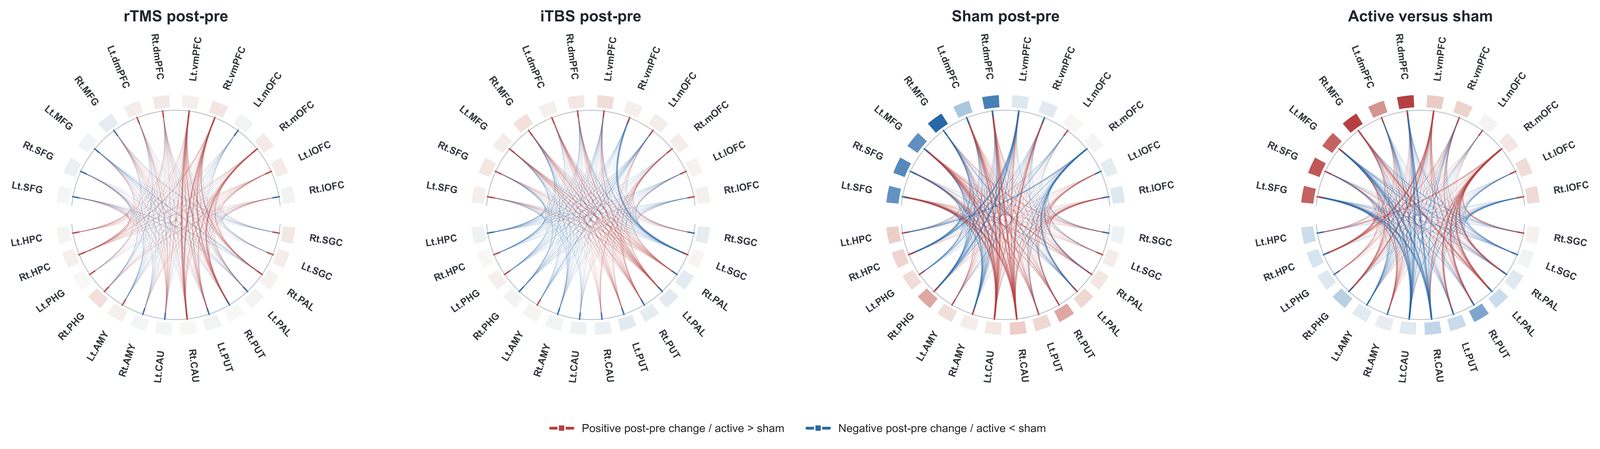

**`outputs/main_analyses/04_figures/corticolimbic_circular_rtms_post_pre.png`**

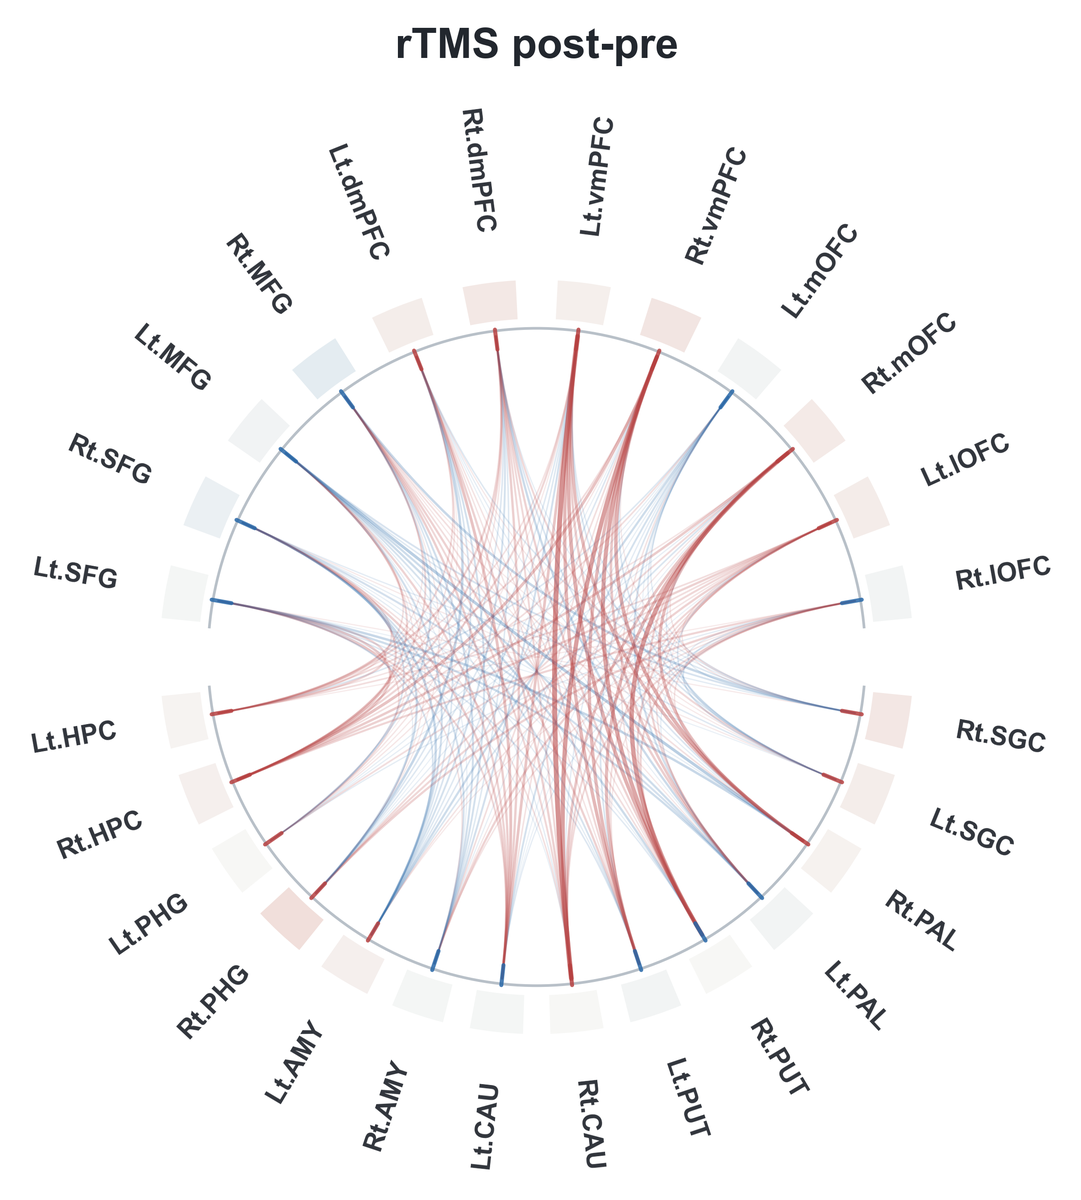

**`outputs/main_analyses/04_figures/corticolimbic_circular_itbs_post_pre.png`**

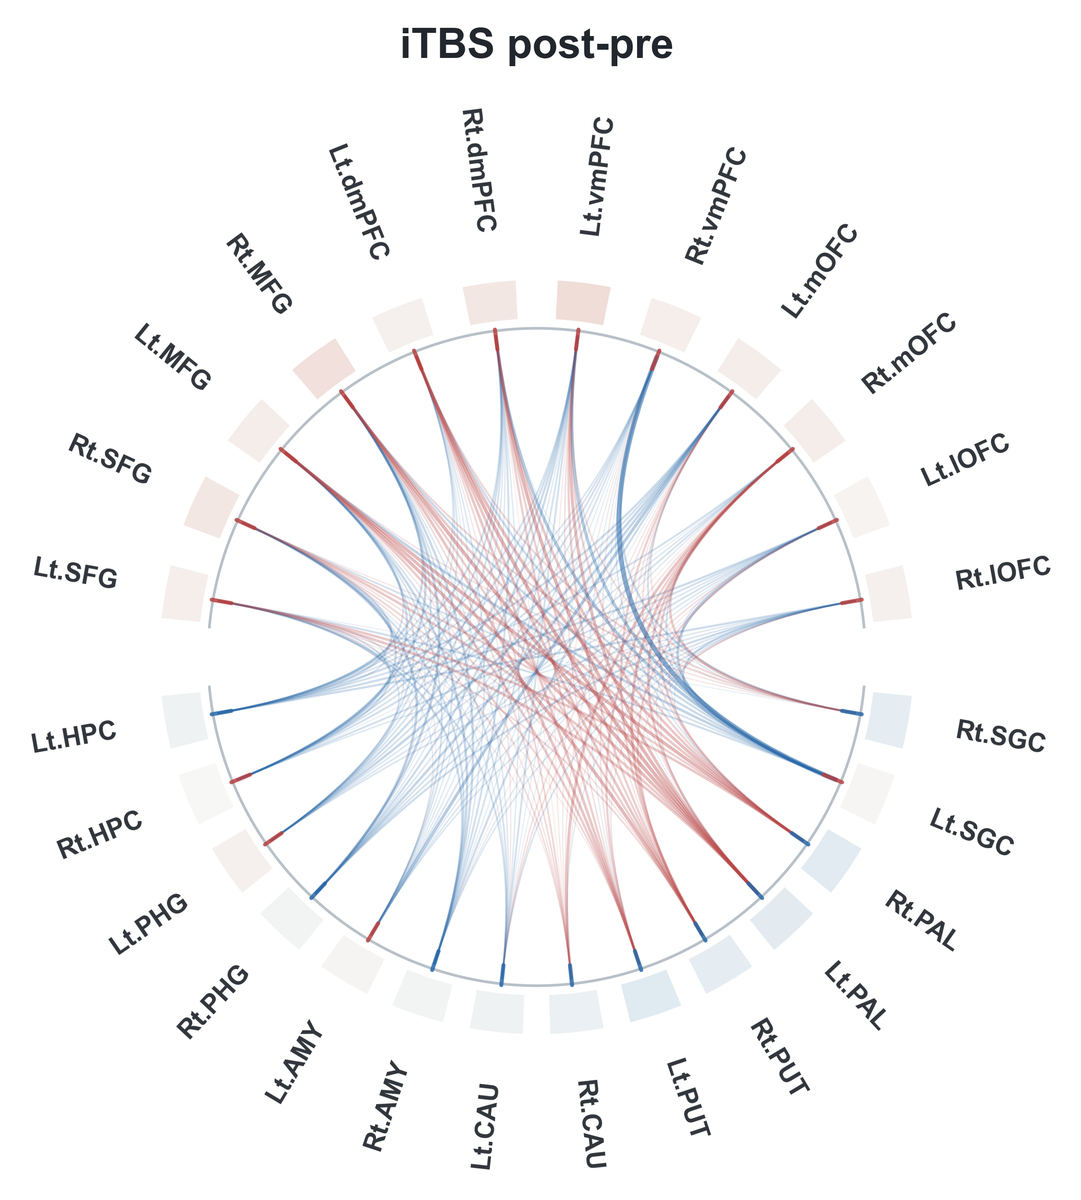

**`outputs/main_analyses/04_figures/corticolimbic_circular_sham_post_pre.png`**

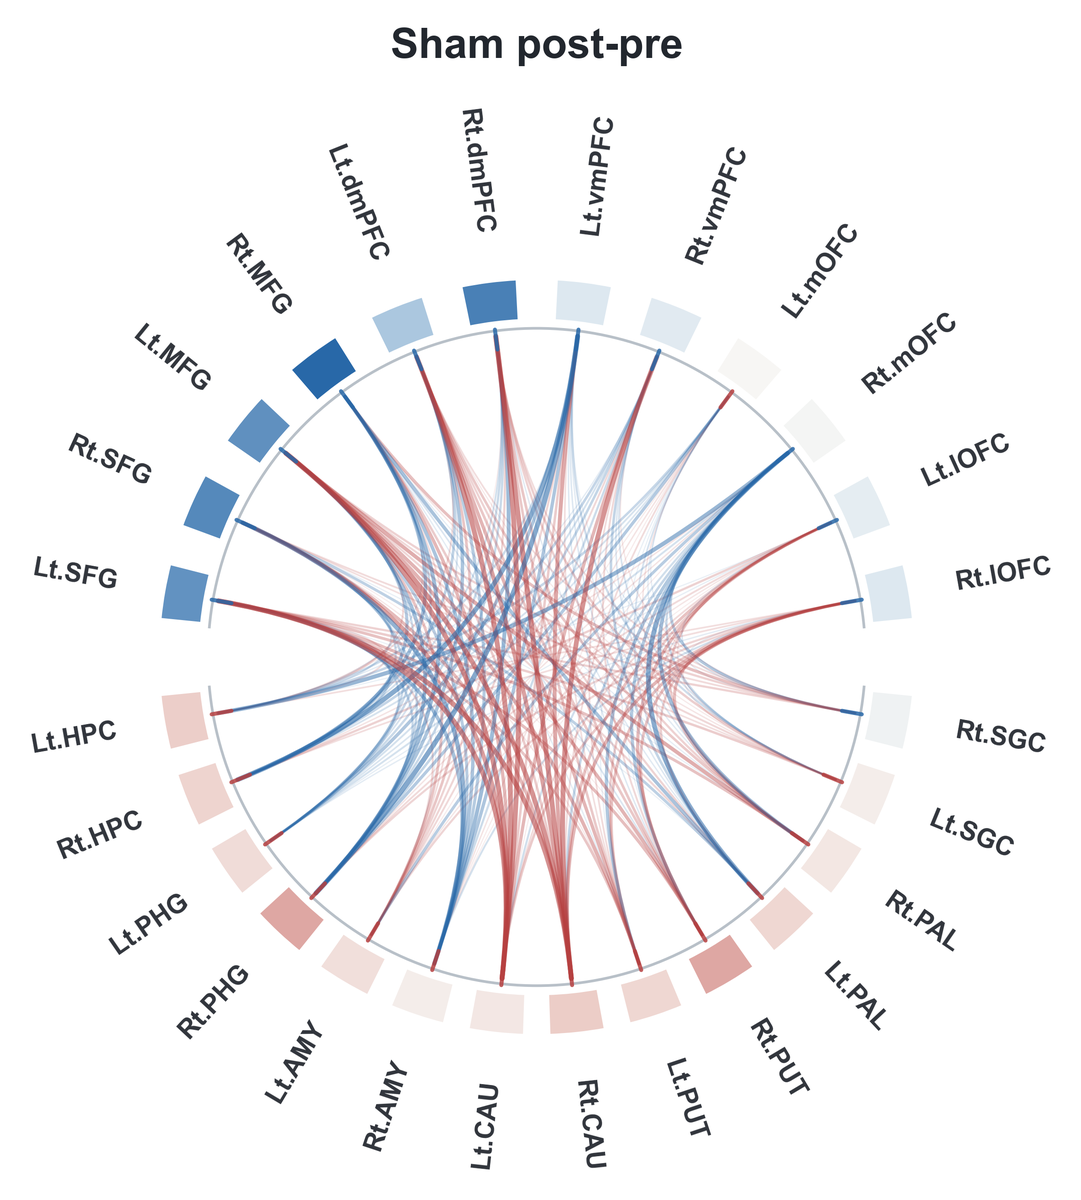

**`outputs/main_analyses/04_figures/corticolimbic_circular_active_vs_sham.png`**

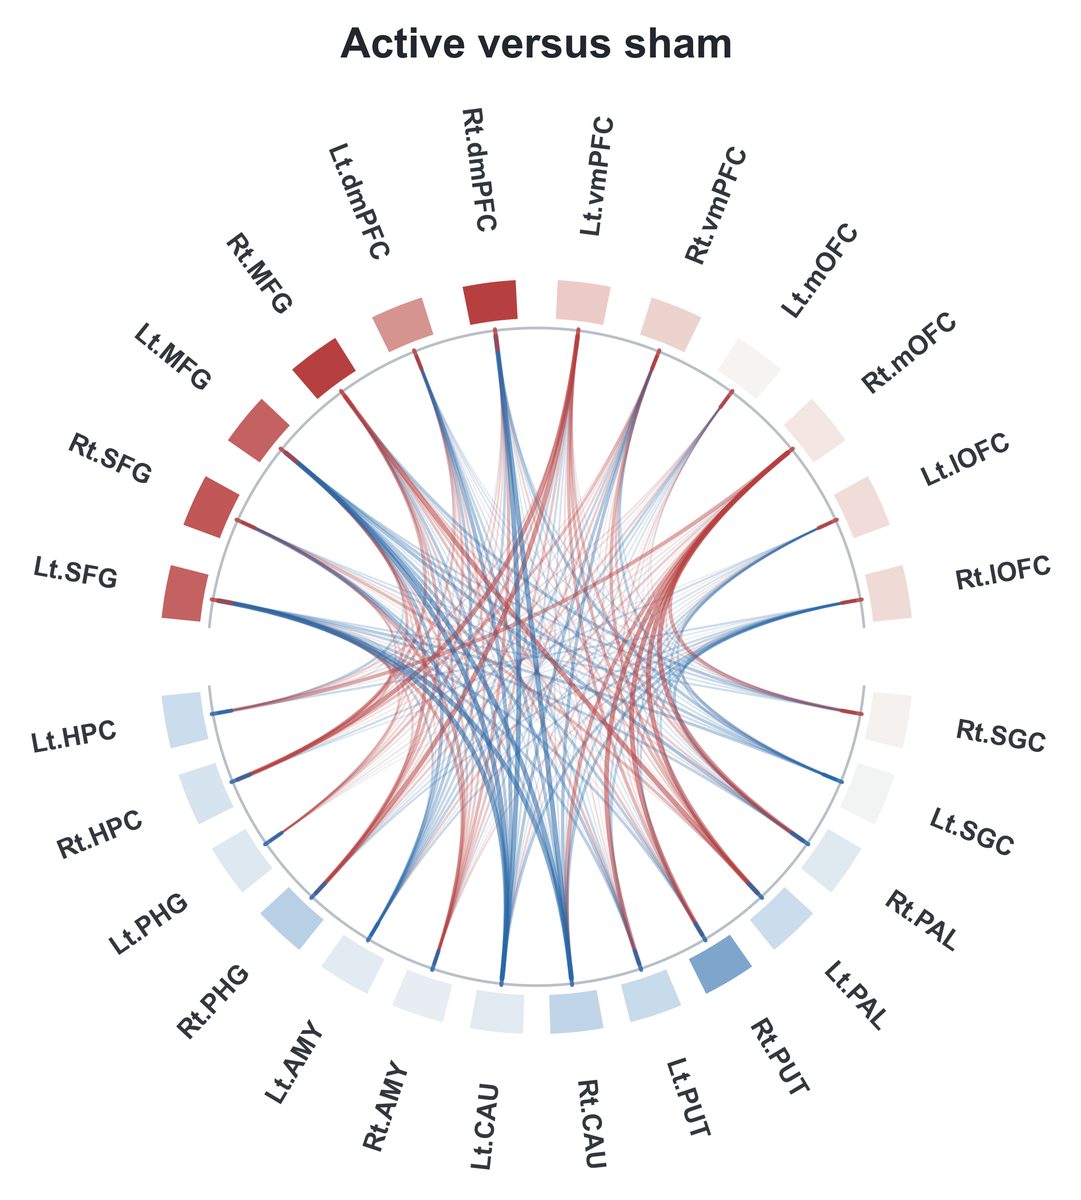

**`outputs/main_analyses/11_SGC_26ROI_figures/figures/corticolimbic_circular_26ROI_bilateral_SGC_TRD_vs_nonTRD_baseline_severity_adjusted.png`**

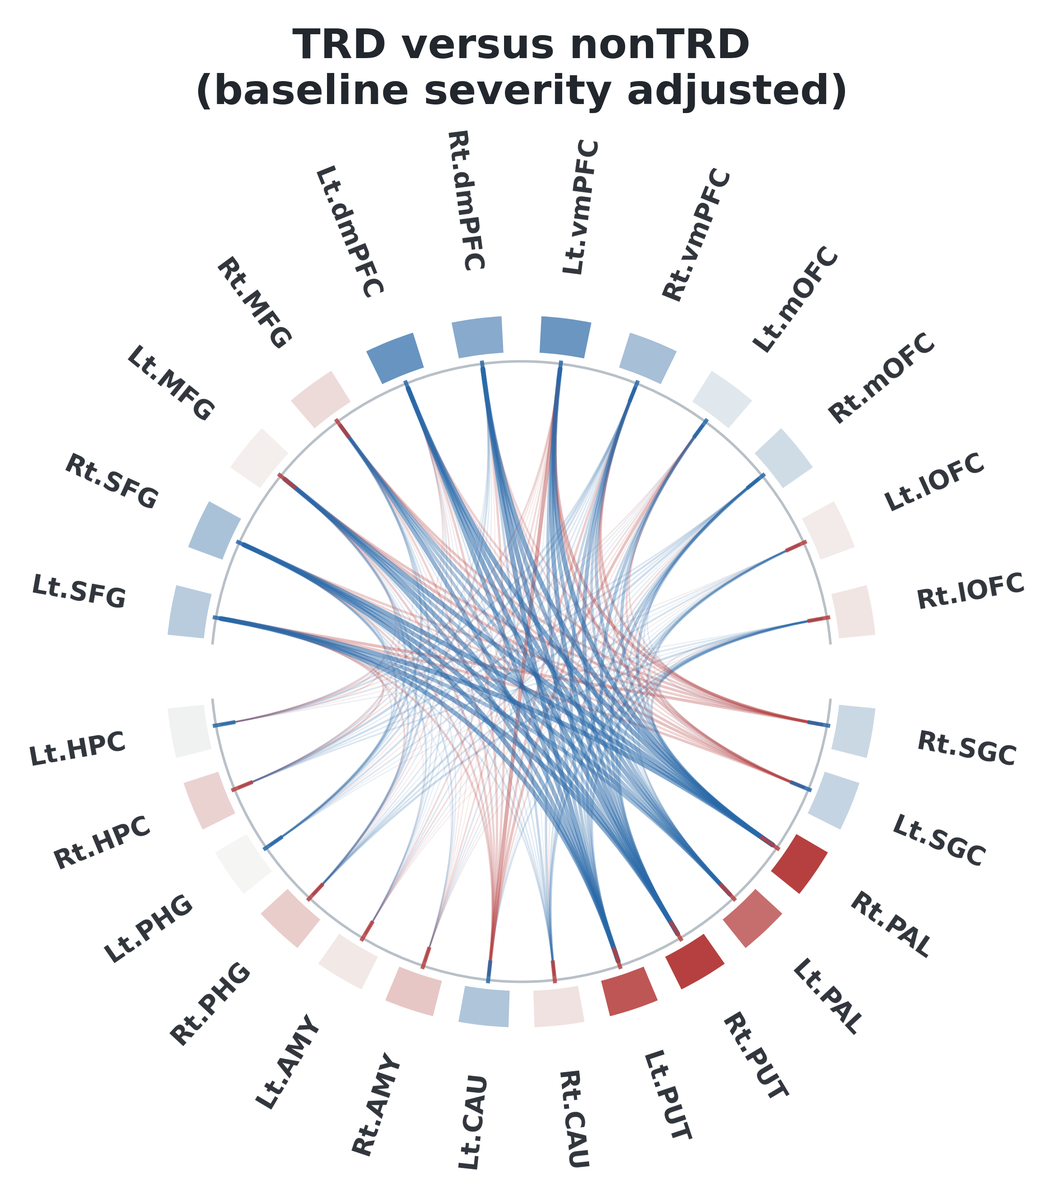

**`outputs/main_analyses/11_SGC_26ROI_figures/figures/Figure_TRD_vs_nonTRD_significant_MwC_nilearn_glass_brain.png`**

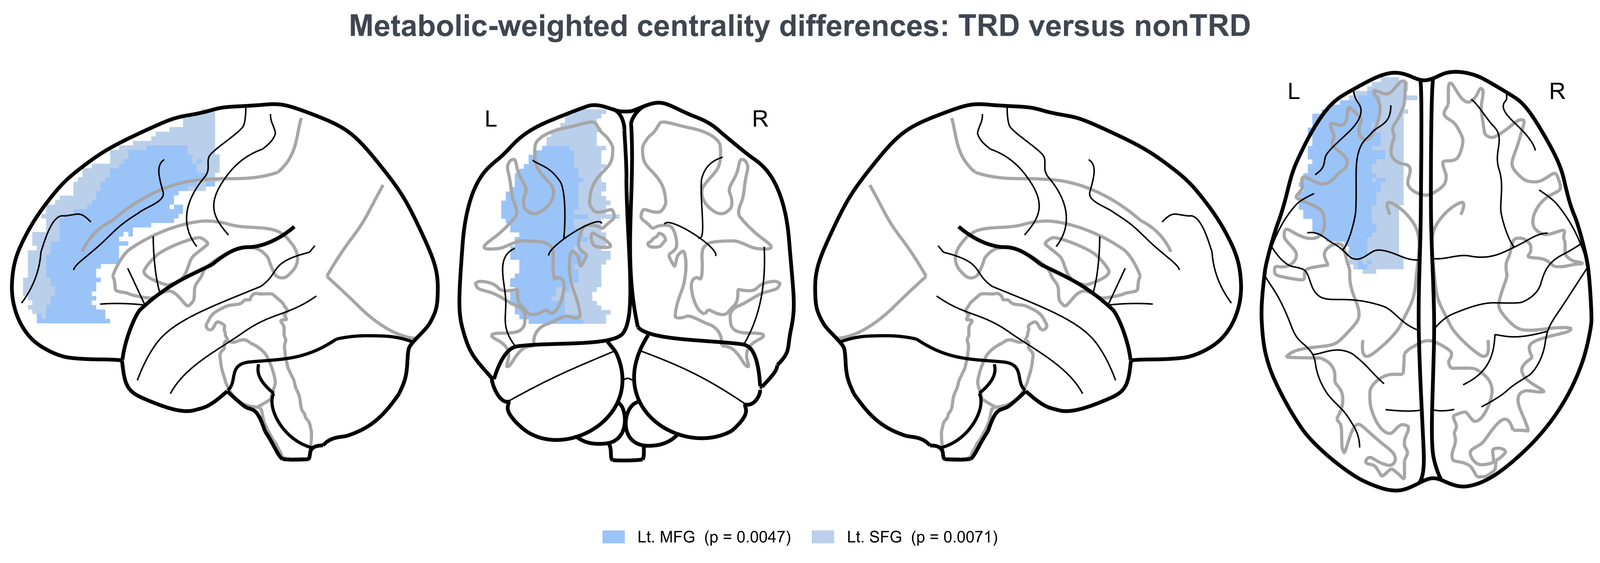

**`outputs/main_analyses/13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_vmPFC_dmPFC_medialOFC_sampled_blue_nilearn_glass_brain.png`**

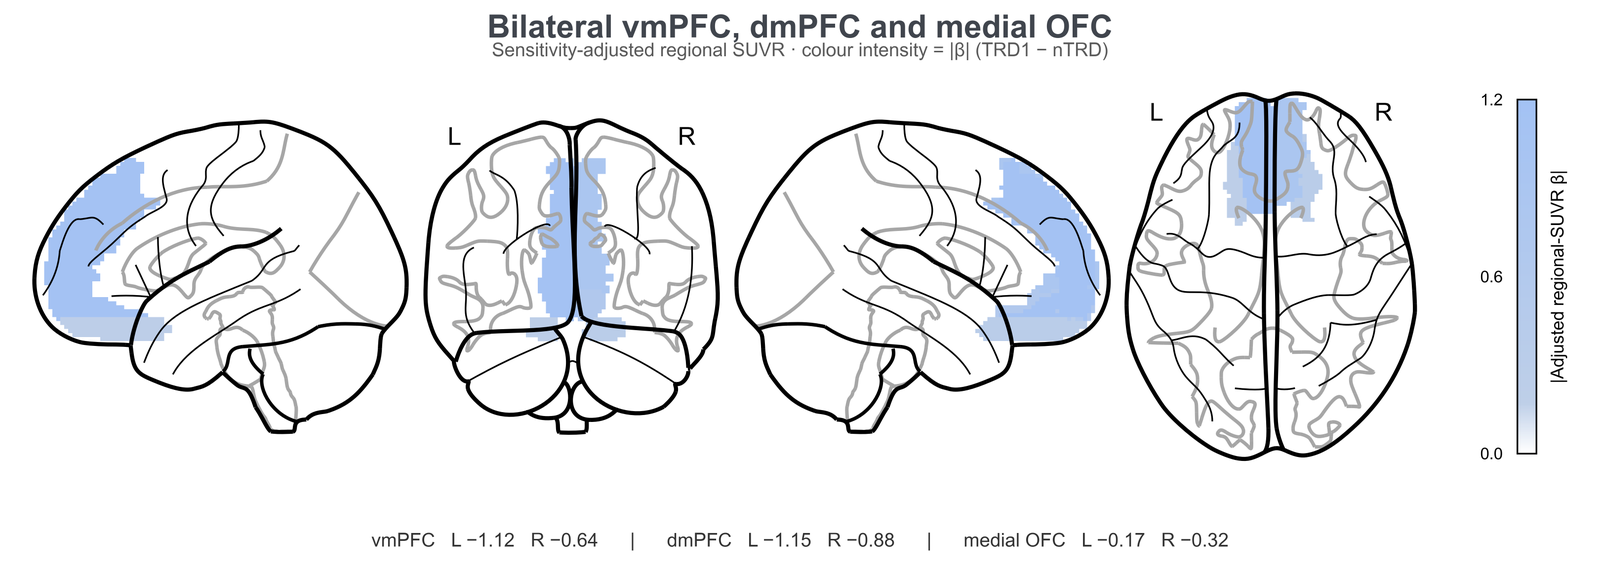

**`outputs/main_analyses/13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_caudate_putamen_pallidum_sampled_pink_nilearn_glass_brain.png`**

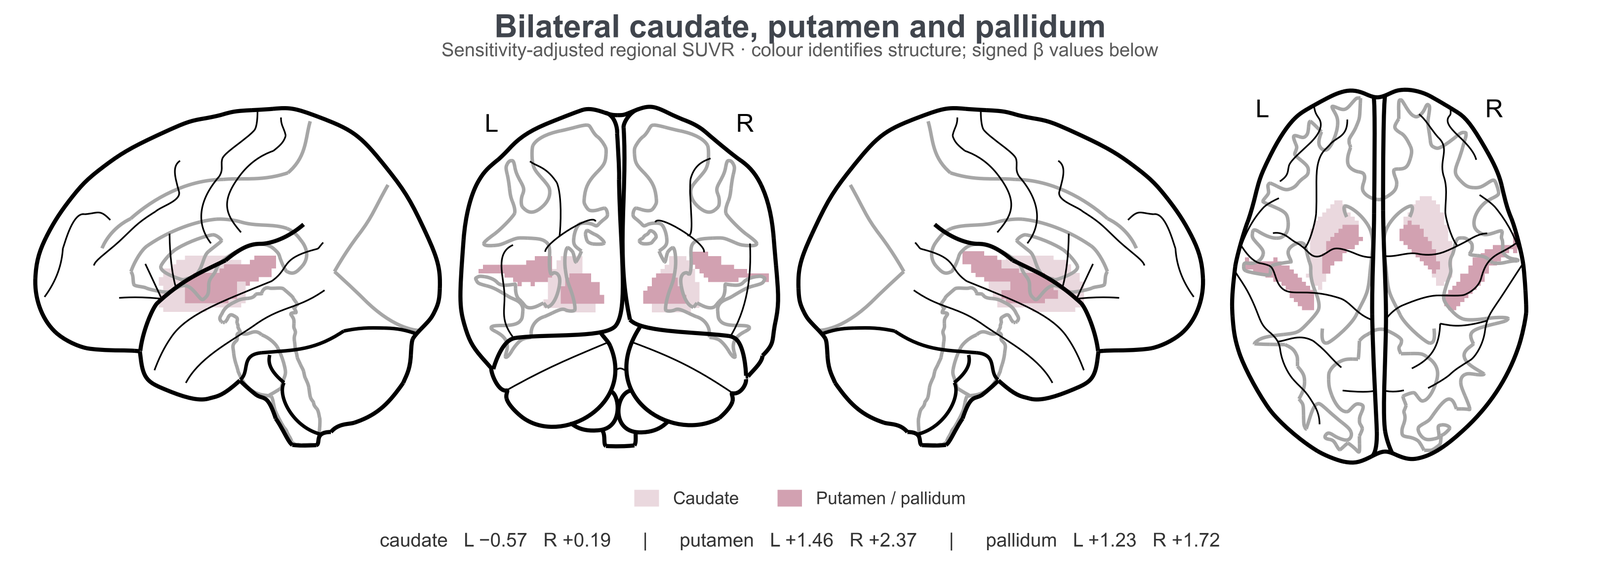

**`outputs/main_analyses/15_nonTRD_TRD_significant_regional_SUVR_glass_brain/figures/Figure_TRD_vs_nonTRD_significant_regional_SUVR_combined_nilearn_glass_brain.png`**

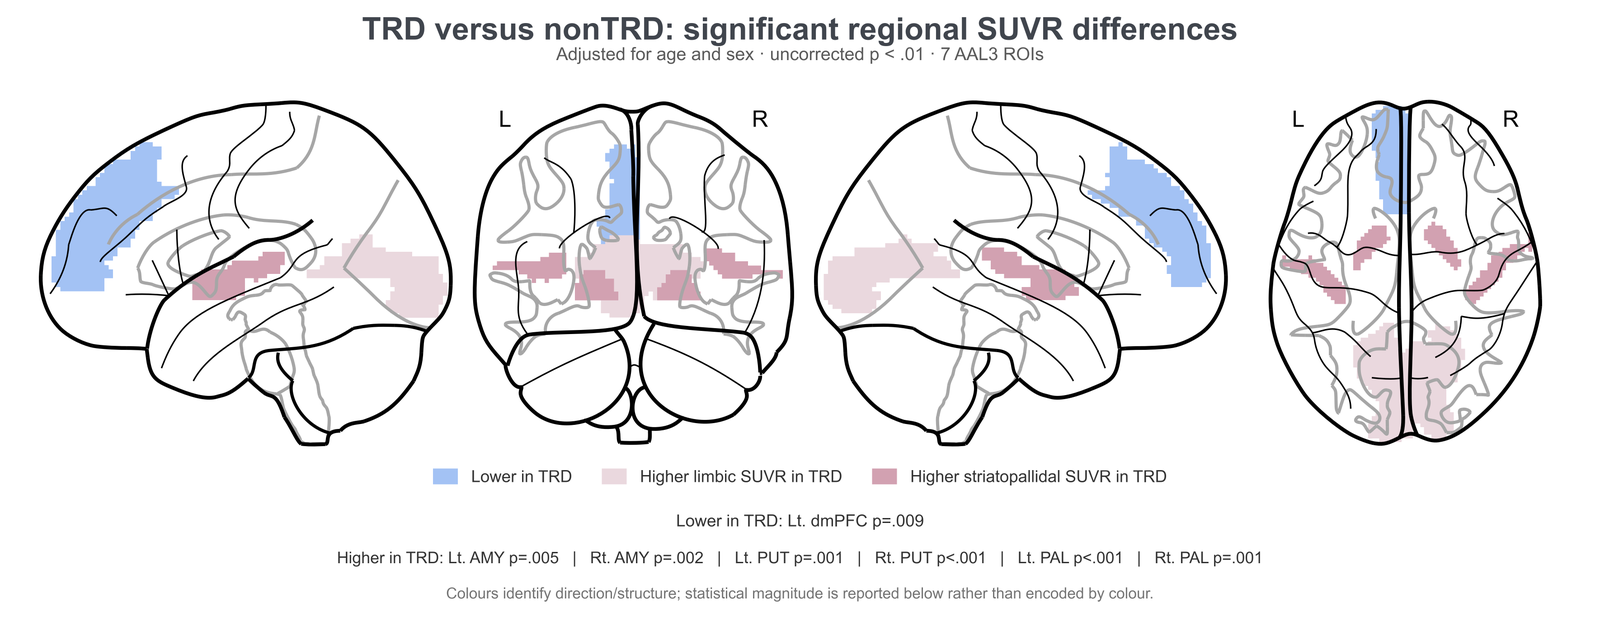

In [6]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'Longitudinal connectivity effects', 'path': 'outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_effects_data.xlsx', 'sheet': 'connectivity_edges', 'max_rows': 30}, {'title': 'Baseline-severity-adjusted regional results', 'path': 'outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv', 'query': 'p_uncorrected < 0.05', 'max_rows': 30}, {'title': 'Baseline-severity-adjusted connectivity results', 'path': 'outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_connectivity168_SGC.csv', 'query': 'p_uncorrected < 0.05', 'max_rows': 30}]
_inline_figure_paths = ['outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_summary.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_rtms_post_pre.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_itbs_post_pre.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_sham_post_pre.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_active_vs_sham.png', 'outputs/main_analyses/11_SGC_26ROI_figures/figures/corticolimbic_circular_26ROI_bilateral_SGC_TRD_vs_nonTRD_baseline_severity_adjusted.png', 'outputs/main_analyses/11_SGC_26ROI_figures/figures/Figure_TRD_vs_nonTRD_significant_MwC_nilearn_glass_brain.png', 'outputs/main_analyses/13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_vmPFC_dmPFC_medialOFC_sampled_blue_nilearn_glass_brain.png', 'outputs/main_analyses/13_sensitivity_mPFC_striatopallidal_glass_brain/figures/Figure_sensitivity_adjusted_bilateral_caudate_putamen_pallidum_sampled_pink_nilearn_glass_brain.png', 'outputs/main_analyses/15_nonTRD_TRD_significant_regional_SUVR_glass_brain/figures/Figure_TRD_vs_nonTRD_significant_regional_SUVR_combined_nilearn_glass_brain.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
